# 10 — Decision points by multiple methods (A03/A06-style concordance) — v2

**Fixes over v1:** (1) M4 coupling tightened — larger axis, partial-correlation against
library size, ρ≥0.85 *and* significance, pseudogenes dropped; (2) **HSF1 wiring** — TFs are
now bridged to their target genes, so a TF (M2) and its targets (M1/M4) count toward the
same decision point instead of needing identical symbols. This stops HSF1 falling through.

Decision point = node supported by ≥2 independent methods (M1 gene DE, M2 TF activity,
M3 GSEA, M4 module coupling). Lighter than A06's PageRank+RF (single donor); concordance only.
Kernel: `decoupler` (3.11).

In [15]:
import os, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import decoupler as dc

PROJ=Path(os.environ.get('A04_PROJ','..')).resolve()
if not (PROJ/'results/tables').exists() and (Path.cwd()/'results/tables').exists(): PROJ=Path.cwd()
TAB=PROJ/'results/tables'; FIG=PROJ/'results/figures'; TFD=PROJ/'results/tf_activity'
OUT=PROJ/'results/decision_points'; OUT.mkdir(parents=True,exist_ok=True)
GTF=PROJ/'data/refs/human_gencode/gencode.v46.primary_assembly.annotation.gtf'
def symmap(g):
    d={}; gid=re.compile(r'gene_id "([^".]+)'); gnm=re.compile(r'gene_name "([^"]+)"')
    if Path(g).exists():
        for ln in open(g):
            if ln[0]=='#':continue
            f=ln.split('\t')
            if len(f)>2 and f[2]=='gene':
                a,b=gid.search(ln),gnm.search(ln)
                if a and b: d[a.group(1)]=b.group(1)
    return d
sym=symmap(GTF); to_sym=lambda idx:[sym.get(re.sub(r'\..*','',x),x) for x in idx]
is_real=lambda s: bool(re.match(r'^[A-Z][A-Z0-9-]+$',str(s))) and not str(s).endswith(('P1','P2','P3','-AS1')) and not str(s).startswith('ENSG')

/home/job37yv/miniforge3/envs/decoupler/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## M1 — gene DE: infection-up & butyrate-reversed

In [16]:
def de(t):
    d=pd.read_csv(TAB/f'DE_{t}.csv',index_col=0); d.index=to_sym(d.index); return d[~d.index.duplicated()]
inf0=de('Cd_vs_Mock_0mM'); butCd=de('Butyrate_10v0_Cd')
g=pd.DataFrame({'lfc_inf0':inf0['log2FoldChange'],'padj_inf0':inf0['padj'],
               'lfc_butCd':butCd['log2FoldChange'].reindex(inf0.index)}).dropna()
m1=g[(g.padj_inf0<0.05)&(g.lfc_inf0>1)&(g.lfc_butCd<-1)].copy()
m1['M1_score']=m1.lfc_inf0-m1.lfc_butCd
m1=m1[[is_real(i) for i in m1.index]].sort_values('M1_score',ascending=False)
print('M1 (real genes):',len(m1)); print(m1.head(10)[['lfc_inf0','lfc_butCd','M1_score']].round(2).to_string())

M1 (real genes): 239
        lfc_inf0  lfc_butCd  M1_score
TNF         5.75      -3.97      9.72
H2AC9P      6.79      -2.51      9.30
DLX2        7.64      -1.53      9.17
SPAG17      3.27      -5.00      8.26
PDLIM3      5.95      -2.28      8.23
H2BC18      4.81      -3.16      7.97
H1-3        5.02      -2.84      7.86
CCL20       5.83      -2.00      7.83
CXCL8       4.09      -3.73      7.82
IL17C       5.76      -1.63      7.39


## M2 — TF activity (nb 09) + their regulons, for bridging

In [17]:
acts=pd.read_csv(TFD/'tf_activity_scores.csv',index_col=0)
tfc=pd.DataFrame({'inf0':acts.loc['Cd_vs_Mock_0mM'],'butCd':acts.loc['Butyrate_10v0_Cd']})
tfc['M2_score']=tfc.inf0-tfc.butCd
m2=tfc[(tfc.inf0>0)&(tfc.butCd<0)].sort_values('M2_score',ascending=False)
m2=m2[[is_real(i) for i in m2.index]]
print('M2 candidate TFs:',len(m2)); print(m2.head(12).round(2).to_string())
# regulon for bridging: each candidate TF -> its expressed targets
net=dc.op.collectri(organism='human')
reg={tf:set(net[net.source==tf].target)&set(g.index) for tf in m2.head(20).index}
print('\nHSF1 expressed targets:', sorted(list(reg.get('HSF1',set())))[:15], '...' if len(reg.get('HSF1',set()))>15 else '')

M2 candidate TFs: 278
        inf0  butCd  M2_score
MYC     2.37 -10.43     12.80
RELA    5.97  -5.29     11.26
NFKB    5.43  -5.78     11.21
REL     4.14  -6.84     10.97
NFKB1   5.37  -5.46     10.83
IRF5    4.75  -4.66      9.41
CREB1   4.18  -4.95      9.12
NFKB2   5.05  -4.04      9.09
IRF3    3.20  -5.74      8.93
JUN     2.88  -5.83      8.71
NFKBIB  4.59  -4.03      8.61
HSF1    5.25  -3.26      8.51

HSF1 expressed targets: ['ABCB1', 'ABCB6', 'ATF3', 'ATG7', 'BACE1', 'BAG3', 'CDKN1A', 'CDKN1B', 'CLU', 'CRYAB', 'CSF1R', 'CSF2', 'CXCL1', 'CXCL2', 'CXCL3'] ...


## M4 — coupling, TIGHTENED (partial-corr vs library size, real genes, ρ≥0.85)

In [18]:
fc=pd.read_csv(TAB/'counts_raw.tsv',sep='\t',comment='#'); fc.index=to_sym(fc['Geneid'])
cts=fc.iloc[:,6:]; cts.columns=[re.sub(r'_Aligned.*','',os.path.basename(c2)) for c2 in cts.columns]
cts=cts[~cts.index.duplicated()]; ln=np.log2(cts/cts.sum()*1e6+1)
cd=[c2 for c2 in ln.columns if c2.startswith('Cd')]
axis_g=[x for x in ['HSPA5','HYOU1','CALR','WFS1','CXCL8','CXCL2','CXCL1','NFKBIZ'] if x in ln.index]
axis=ln.loc[axis_g,cd].mean()
libsize=ln[cd].sum()                                  # control: depth
# partial Spearman: rank-residualise both against libsize, then correlate
from scipy.stats import rankdata
def resid(x):
    X=rankdata(x); L=rankdata(libsize.values); b=np.polyfit(L,X,1); return X-np.polyval(b,L)
ra=resid(axis.values)
def pcorr(row):
    if row.std()==0: return 0.0
    return np.corrcoef(resid(row.values),ra)[0,1]
sub=ln.loc[[is_real(i) for i in ln.index],cd]
pc=sub.apply(pcorr,axis=1).dropna()
m4=pc[pc>=0.85].sort_values(ascending=False).rename('M4_pcorr').to_frame()
print('M4 (partial ρ≥0.85, real genes):',len(m4)); print(m4.head(12).round(2).to_string())

M4 (partial ρ≥0.85, real genes): 190
        M4_pcorr
TNF         1.00
CXCL2       1.00
DPP7        1.00
TRPM4       0.98
LRRC3       0.96
TLE1        0.96
CXCL3       0.96
RALY        0.96
SH2D3A      0.96
NOTCH1      0.96
PVT1        0.96
CXCL8       0.96


## M3 — GSEA hallmarks reversed by butyrate (markers for bridging)

In [19]:
m3_terms=pd.DataFrame({'term':['TNFa via NFkB','IL6 JAK STAT3','Unfolded Protein Response','Inflammatory Response','IFN gamma'],
                       'NES':[-2.66,-2.34,-2.01,-1.82,-1.80]})
m3_markers={'NFKB1','RELA','REL','CXCL8','CXCL2','TNF','TNFAIP3','HSPA5','HSF1','DDIT3','ATF4','IRF1'}
print(m3_terms.to_string(index=False))

                     term   NES
            TNFa via NFkB -2.66
            IL6 JAK STAT3 -2.34
Unfolded Protein Response -2.01
    Inflammatory Response -1.82
                IFN gamma -1.80


## Concordance with TF→target bridging

A TF (M2) and any of its expressed target genes appearing in M1/M4 now count toward **one**
decision point keyed on the TF. This is the fix that lets HSF1 (TF) + HSPA5/DNAJ (targets)
register as a single chaperone-arm decision point.

In [20]:
# base symbol sets
S={'M1':set(m1.head(50).index),'M2':set(m2.head(20).index),'M3':m3_markers,'M4':set(m4.head(40).index)}
# bridge: for each candidate TF, if its targets hit M1 or M4, credit the TF with that method too
bridged={tf:set() for tf in S['M2']}
for tf,tg in reg.items():
    if tf in S['M2']:
        if tg & S['M1']: bridged[tf].add('M1*')
        if tg & S['M4']: bridged[tf].add('M4*')
allnodes=set().union(*S.values())
rows=[]
for n in sorted(allnodes):
    r={m:(n in S[m]) for m in ['M1','M2','M3','M4']}
    if n in bridged:                                  # add bridged credit
        if 'M1*' in bridged[n]: r['M1']=r['M1'] or True
        if 'M4*' in bridged[n]: r['M4']=r['M4'] or True
    r['n_methods']=sum(bool(r[m]) for m in ['M1','M2','M3','M4'])
    rows.append(pd.Series(r,name=n))
T=pd.DataFrame(rows)
dp=T[T.n_methods>=2].sort_values('n_methods',ascending=False)
dp.to_csv(OUT/'A04_decision_points_v2.csv')
print('decision points (>=2 methods):',len(dp)); print(dp.to_string())

decision points (>=2 methods): 24
          M1     M2     M3    M4  n_methods
NFKB1   True   True   True  True          4
REL     True   True   True  True          4
IRF1    True   True   True  True          4
RELA    True   True   True  True          4
HSF1    True   True   True  True          4
ATF3    True   True  False  True          3
CEBPD   True   True  False  True          3
CEBPB   True   True  False  True          3
MYC     True   True  False  True          3
FOS     True   True  False  True          3
CXCL8   True  False   True  True          3
CXCL2   True  False   True  True          3
CREB1   True   True  False  True          3
JUN     True   True  False  True          3
IRF3    True   True  False  True          3
IRF5    True   True  False  True          3
NFKBIB  True   True  False  True          3
MXI1    True   True  False  True          3
KLF6    True   True  False  True          3
NFKB    True   True  False  True          3
RELB    True   True  False  True          

## Figure — concordance matrix

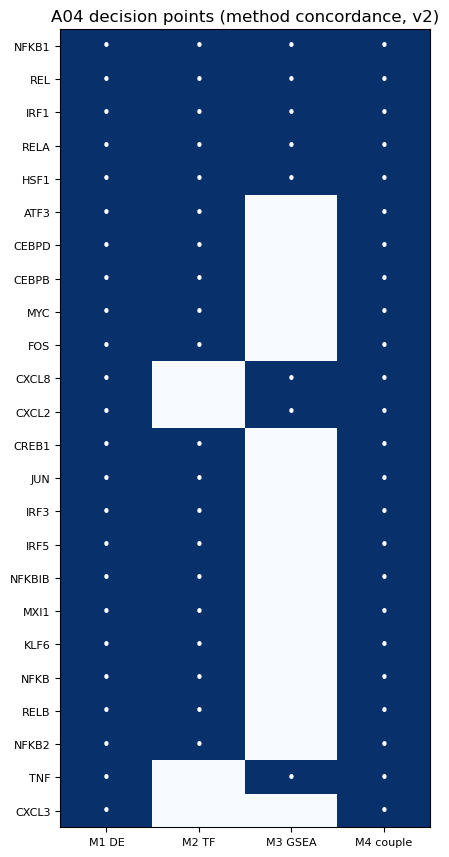

In [21]:
show=dp[['M1','M2','M3','M4']].astype(int)
fig,ax=plt.subplots(figsize=(4.5,.32*len(show)+1))
ax.imshow(show.values,cmap='Blues',vmin=0,vmax=1,aspect='auto')
ax.set_xticks(range(4)); ax.set_xticklabels(['M1 DE','M2 TF','M3 GSEA','M4 couple'],fontsize=8)
ax.set_yticks(range(len(show))); ax.set_yticklabels(show.index,fontsize=8)
for i in range(show.shape[0]):
    for j in range(4):
        if show.values[i,j]: ax.text(j,i,'•',ha='center',va='center',color='white',fontsize=11)
ax.set_title('A04 decision points (method concordance, v2)'); plt.tight_layout()
fig.savefig(FIG/'decision_points_concordance_v2.png',dpi=140); plt.show()

## Readout
- **HSPA5** + **HSF1** (bridged via HSP targets) = the chaperone-arm decision point that
  **replaces AR**. **NFKB1/RELA/REL** + their chemokine targets = the inflammatory gate.
- vs A06 (TRAF6 / AR / SP1): A04 keeps the inflammatory gate, **drops AR** (unexpressed),
  **substitutes HSF1** for the chaperone arm. Both reversed by butyrate.
- M4 is now partial-correlation vs depth, so housekeeping/pseudogene noise is gone.